In [2]:
import os

for root, dirs, files in os.walk("/content"):
    for file in files:
        print(os.path.join(root, file))

/content/Time-Series Data (1).csv
/content/.config/active_config
/content/.config/default_configs.db
/content/.config/hidden_gcloud_config_universe_descriptor_data_cache_configs.db
/content/.config/gce
/content/.config/config_sentinel
/content/.config/.last_update_check.json
/content/.config/.last_opt_in_prompt.yaml
/content/.config/.last_survey_prompt.yaml
/content/.config/logs/2026.10.17/23.08.48.139029.log
/content/.config/logs/2026.10.17/23.08.21.541362.log
/content/.config/logs/2026.10.17/23.08.57.460113.log
/content/.config/logs/2026.10.17/23.09.06.764677.log
/content/.config/logs/2026.10.17/23.08.58.561612.log
/content/.config/logs/2026.10.17/23.09.06.201823.log
/content/.config/configurations/config_default
/content/sample_data/anscombe.json
/content/sample_data/README.md
/content/sample_data/california_housing_test.csv
/content/sample_data/mnist_train_small.csv
/content/sample_data/california_housing_train.csv
/content/sample_data/mnist_test.csv


In [3]:
import os
import glob
import zipfile
import pandas as pd

# Find uploaded CSV and ZIP files
files = glob.glob("/content/**/*.csv", recursive=True)
zip_files = glob.glob("/content/**/*.zip", recursive=True)

print("CSV files:", files)
print("ZIP files:", zip_files)

CSV files: ['/content/Time-Series Data (1).csv', '/content/sample_data/california_housing_test.csv', '/content/sample_data/mnist_train_small.csv', '/content/sample_data/california_housing_train.csv', '/content/sample_data/mnist_test.csv']
ZIP files: []


In [4]:
# Load a CSV directly, or find one inside a ZIP file
if files:
    file_path = files[0]
    df = pd.read_csv(file_path)
elif zip_files:
    with zipfile.ZipFile(zip_files[0]) as z:
        csv_files = [f for f in z.namelist()
                     if f.lower().endswith(".csv")]
        print("CSV files inside ZIP:", csv_files)

        if csv_files:
            with z.open(csv_files[0]) as f:
                df = pd.read_csv(f)
        else:
            raise ValueError("No CSV file found inside the ZIP.")
else:
    raise FileNotFoundError("No CSV or ZIP file found in /content.")

print("Dataset shape:", df.shape)
print("Columns:", df.columns.tolist())
display(df.head())

Dataset shape: (421, 2)
Columns: ['date', 'users']


,date,users
0,01-07-2020,2324
1,02-07-2020,2201
2,03-07-2020,2146
3,04-07-2020,1666
4,05-07-2020,1433


In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Convert date into datetime format
df['date'] = pd.to_datetime(
    df['date'], format='%d-%m-%Y'
)

# Sort data chronologically
df = df.sort_values('date').reset_index(drop=True)

# Check missing values
print("Missing values before handling:")
print(df.isnull().sum())

# Handle missing values
df['users'] = df['users'].interpolate(
    method='linear'
)

# Handle any remaining missing values at the beginning or end
df['users'] = df['users'].ffill().bfill()

print("\nMissing values after handling:")
print(df.isnull().sum())

print("\nDataset information:")
print(df.info())
print("\nFirst 5 rows:")
display(df.head())

Missing values before handling:
date     0
users    0
dtype: int64

Missing values after handling:
date     0
users    0
dtype: int64

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 421 entries, 0 to 420
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype         
---  ------  --------------  -----         
 0   date    421 non-null    datetime64[ns]
 1   users   421 non-null    int64         
dtypes: datetime64[ns](1), int64(1)
memory usage: 6.7 KB
None

First 5 rows:


,date,users
0,2020-07-01,2324
1,2020-07-02,2201
2,2020-07-03,2146
3,2020-07-04,1666
4,2020-07-05,1433


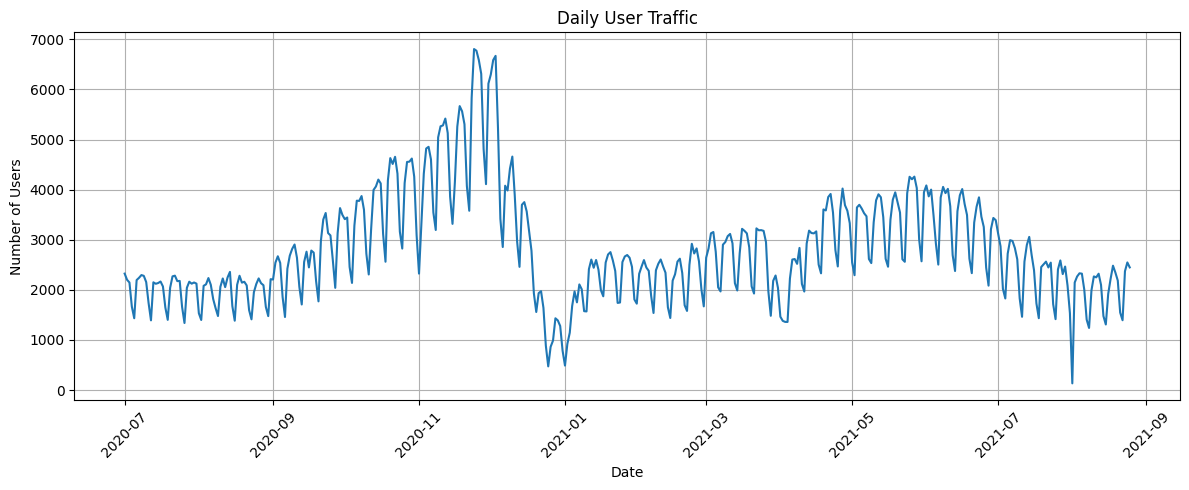

In [6]:
plt.figure(figsize=(12, 5))

plt.plot(df['date'], df['users'])

plt.title('Daily User Traffic')
plt.xlabel('Date')
plt.ylabel('Number of Users')
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

In [7]:
from sklearn.preprocessing import MinMaxScaler

# Scale user counts between 0 and 1
scaler = MinMaxScaler()

values = df[['users']].values.astype('float32')

split = int(len(values) * 0.8)

# Fit scaler only on training data
train_scaled = scaler.fit_transform(values[:split])
test_scaled = scaler.transform(values[split:])

# Combine scaled data so test sequences can use
# the preceding 30 days of training history
all_scaled = np.vstack([train_scaled, test_scaled])

window_size = 30

X_train, y_train = [], []
X_test, y_test = [], []

for i in range(window_size, split):
    X_train.append(all_scaled[i-window_size:i, 0])
    y_train.append(all_scaled[i, 0])

for i in range(split, len(all_scaled)):
    X_test.append(all_scaled[i-window_size:i, 0])
    y_test.append(all_scaled[i, 0])

X_train = np.array(X_train)
y_train = np.array(y_train)
X_test = np.array(X_test)
y_test = np.array(y_test)

# LSTM expects [samples, time steps, features]
X_train = X_train.reshape(-1, window_size, 1)
X_test = X_test.reshape(-1, window_size, 1)

print("Training input shape:", X_train.shape)
print("Training target shape:", y_train.shape)
print("Testing input shape:", X_test.shape)
print("Testing target shape:", y_test.shape)

Training input shape: (306, 30, 1)
Training target shape: (306,)
Testing input shape: (85, 30, 1)
Testing target shape: (85,)


In [8]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

# Make results more reproducible
tf.random.set_seed(42)
np.random.seed(42)

# Build LSTM model
model = Sequential([
    LSTM(64, return_sequences=True,
         input_shape=(window_size, 1)),
    Dropout(0.2),
    LSTM(32),
    Dropout(0.2),
    Dense(16, activation='relu'),
    Dense(1)
])

model.compile(
    optimizer='adam',
    loss='mean_squared_error'
)

# Stop training when validation loss stops improving
early_stop = EarlyStopping(
    monitor='val_loss',
    patience=8,
    restore_best_weights=True
)

history = model.fit(
    X_train,
    y_train,
    epochs=50,
    batch_size=16,
    validation_split=0.1,
    callbacks=[early_stop],
    shuffle=False,
    verbose=1
)

print("Model training completed!")

Epoch 1/50


/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


18/18 ━━━━━━━━━━━━━━━━━━━━ 5s 48ms/step - loss: 0.0500 - val_loss: 0.0155
Epoch 2/50
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step - loss: 0.0262 - val_loss: 0.0093
Epoch 3/50
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step - loss: 0.0217 - val_loss: 0.0151
Epoch 4/50
18/18 ━━━━━━━━━━━━━━━━━━━━ 1s 25ms/step - loss: 0.0206 - val_loss: 0.0101
Epoch 5/50
18/18 ━━━━━━━━━━━━━━━━━━━━ 1s 25ms/step - loss: 0.0175 - val_loss: 0.0117
Epoch 6/50
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step - loss: 0.0185 - val_loss: 0.0124
Epoch 7/50
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step - loss: 0.0164 - val_loss: 0.0122
Epoch 8/50
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step - loss: 0.0164 - val_loss: 0.0109
Epoch 9/50
18/18 ━━━━━━━━━━━━━━━━━━━━ 1s 25ms/step - loss: 0.0180 - val_loss: 0.0102
Epoch 10/50
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step - loss: 0.0153 - val_loss: 0.0131
Model training completed!


In [9]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

# Predict user traffic
pred_scaled = model.predict(X_test)

# Convert predictions back to original user counts
y_actual = scaler.inverse_transform(
    y_test.reshape(-1, 1)
).flatten()

y_predicted = scaler.inverse_transform(
    pred_scaled
).flatten()

# Calculate evaluation metrics
mae = mean_absolute_error(y_actual, y_predicted)
rmse = np.sqrt(mean_squared_error(y_actual, y_predicted))

print("MAE:", round(mae, 2))
print("RMSE:", round(rmse, 2))

3/3 ━━━━━━━━━━━━━━━━━━━━ 1s 153ms/step
MAE: 498.07
RMSE: 692.67


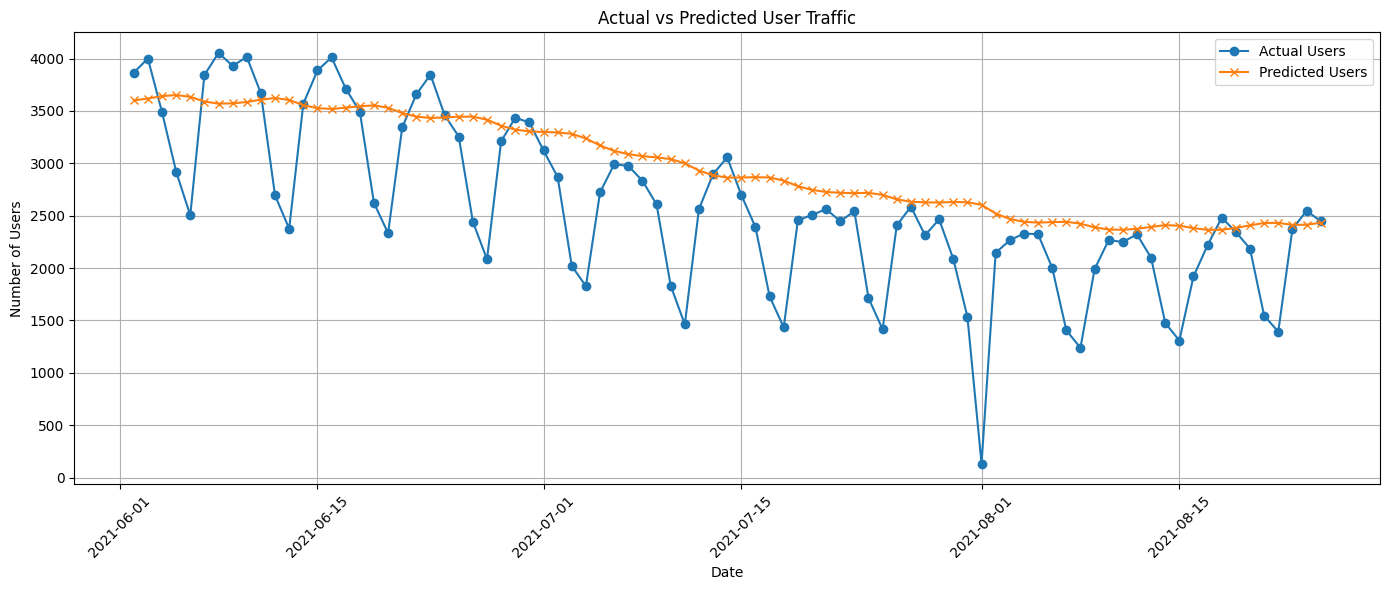

In [10]:
test_dates = df['date'].iloc[split:].reset_index(drop=True)

plt.figure(figsize=(14, 6))

plt.plot(
    test_dates,
    y_actual,
    label='Actual Users',
    marker='o'
)

plt.plot(
    test_dates,
    y_predicted,
    label='Predicted Users',
    marker='x'
)

plt.title('Actual vs Predicted User Traffic')
plt.xlabel('Date')
plt.ylabel('Number of Users')
plt.legend()
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

In [12]:
last_window = all_scaled[-window_size:].copy()
future_predictions = []

for _ in range(7):
    next_pred = model.predict(
        last_window.reshape(1, window_size, 1),
        verbose=0
    )[0, 0]

    future_predictions.append(next_pred)

    last_window = np.concatenate([
        last_window[1:],
        np.array([[next_pred]])
    ])

future_users = scaler.inverse_transform(
    np.array(future_predictions).reshape(-1, 1)
).flatten()

future_dates = pd.date_range(
    start="2025-01-01",
    periods=7
)


forecast_df = pd.DataFrame({
    'date': future_dates,
    'predicted_users': np.round(future_users).astype(int)
})

display(forecast_df)

,date,predicted_users
0,2025-01-01,2459
1,2025-01-02,2490
2,2025-01-03,2523
3,2025-01-04,2558
4,2025-01-05,2593
5,2025-01-06,2628
6,2025-01-07,2663
